# Lab | Neural Networks — Complete Submission

## Challenge 1 — Tic-Tac-Toe Endgame Classification

This notebook solves Challenge 1 from the Ironhack **lab-neural-networks** repository.

**Goal:** build a neural-network classifier that predicts whether a completed Tic-Tac-Toe board is a **positive** state (X wins) or **negative** state (X does not win).

The official UCI Tic-Tac-Toe Endgame dataset contains **958 legal terminal board configurations**, 9 categorical board-position features, and a binary target. To keep this submission fully reproducible, the exact set of 958 terminal states is generated directly from the rules of Tic-Tac-Toe instead of relying on an external download.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Build the Tic-Tac-Toe Endgame dataset

A legal game starts with **X**, alternates turns, and stops immediately when X wins, O wins, or the board becomes full.

By recursively generating every reachable terminal state, we obtain the same **958 endgame configurations** described by the UCI dataset.


In [2]:
WIN_LINES = [
    (0, 1, 2), (3, 4, 5), (6, 7, 8),  # rows
    (0, 3, 6), (1, 4, 7), (2, 5, 8),  # columns
    (0, 4, 8), (2, 4, 6)              # diagonals
]

def has_won(board, player):
    return any(all(board[i] == player for i in line) for line in WIN_LINES)

terminal_states = set()

def generate_games(board=("b",) * 9, turn="x"):
    # Stop as soon as the game reaches a terminal state.
    if has_won(board, "x") or has_won(board, "o") or "b" not in board:
        terminal_states.add(board)
        return

    next_turn = "o" if turn == "x" else "x"

    for idx, value in enumerate(board):
        if value == "b":
            new_board = list(board)
            new_board[idx] = turn
            generate_games(tuple(new_board), next_turn)

generate_games()

column_names = [
    "top-left-square",
    "top-middle-square",
    "top-right-square",
    "middle-left-square",
    "middle-middle-square",
    "middle-right-square",
    "bottom-left-square",
    "bottom-middle-square",
    "bottom-right-square",
]

df = pd.DataFrame(sorted(terminal_states), columns=column_names)
df["class"] = np.where(
    df[column_names].apply(lambda row: has_won(tuple(row), "x"), axis=1),
    "positive",
    "negative"
)

print("Dataset shape:", df.shape)
print("\nClass counts:")
print(df["class"].value_counts())
df.head()

Dataset shape: (958, 10)

Class counts:
class
positive    626
negative    332
Name: count, dtype: int64


,top-left-square,top-middle-square,top-right-square,middle-left-square,middle-middle-square,middle-right-square,bottom-left-square,bottom-middle-square,bottom-right-square,class
0,b,b,b,b,o,o,x,x,x,positive
1,b,b,b,o,b,o,x,x,x,positive
2,b,b,b,o,o,b,x,x,x,positive
3,b,b,b,x,x,x,b,o,o,positive
4,b,b,b,x,x,x,o,b,o,positive


### Dataset checks

The expected size is **958 rows × 10 columns**: nine board positions and one target column.  
There are no missing values because every square is represented as `x`, `o`, or `b` (blank).


In [3]:
print(df.info())
print("\nMissing values:", int(df.isna().sum().sum()))
print("\nUnique values per board square:")
print({col: sorted(df[col].unique().tolist()) for col in column_names})

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   top-left-square       958 non-null    object
 1   top-middle-square     958 non-null    object
 2   top-right-square      958 non-null    object
 3   middle-left-square    958 non-null    object
 4   middle-middle-square  958 non-null    object
 5   middle-right-square   958 non-null    object
 6   bottom-left-square    958 non-null    object
 7   bottom-middle-square  958 non-null    object
 8   bottom-right-square   958 non-null    object
 9   class                 958 non-null    object
dtypes: object(10)
memory usage: 75.0+ KB
None

Missing values: 0

Unique values per board square:
{'top-left-square': ['b', 'o', 'x'], 'top-middle-square': ['b', 'o', 'x'], 'top-right-square': ['b', 'o', 'x'], 'middle-left-square': ['b', 'o', 'x'], 'middle-middle-square': ['b', 'o', 'x'], 'mid

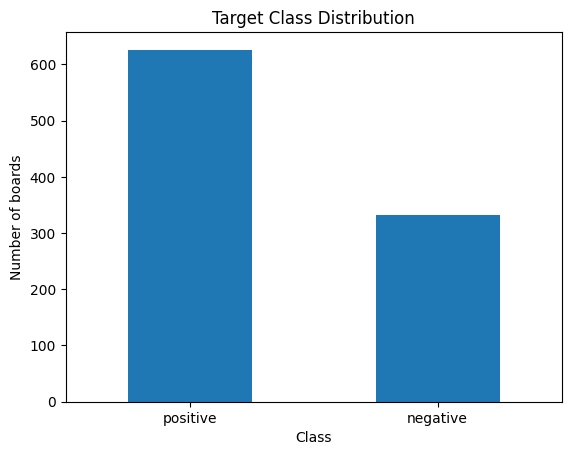

class
positive    65.34%
negative    34.66%
Name: count, dtype: object


In [4]:
class_counts = df["class"].value_counts()
class_counts.plot(kind="bar", title="Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of boards")
plt.xticks(rotation=0)
plt.show()

print((class_counts / len(df) * 100).round(2).astype(str) + "%")

## 2. Encode the categorical board

Neural networks require numeric inputs. Each board position has three possible values:

- `x`
- `o`
- `b` = blank

One-hot encoding avoids imposing an artificial numeric ordering on these symbols.


In [5]:
X = pd.get_dummies(df[column_names], dtype=float)
y = (df["class"] == "positive").astype(int)

print("Encoded feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nEncoded columns:")
print(X.columns.tolist())

Encoded feature matrix shape: (958, 27)
Target shape: (958,)

Encoded columns:
['top-left-square_b', 'top-left-square_o', 'top-left-square_x', 'top-middle-square_b', 'top-middle-square_o', 'top-middle-square_x', 'top-right-square_b', 'top-right-square_o', 'top-right-square_x', 'middle-left-square_b', 'middle-left-square_o', 'middle-left-square_x', 'middle-middle-square_b', 'middle-middle-square_o', 'middle-middle-square_x', 'middle-right-square_b', 'middle-right-square_o', 'middle-right-square_x', 'bottom-left-square_b', 'bottom-left-square_o', 'bottom-left-square_x', 'bottom-middle-square_b', 'bottom-middle-square_o', 'bottom-middle-square_x', 'bottom-right-square_b', 'bottom-right-square_o', 'bottom-right-square_x']


## 3. Train/test split

A stratified split keeps approximately the same positive/negative proportion in both subsets.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Training positive rate:", round(y_train.mean(), 3))
print("Test positive rate:", round(y_test.mean(), 3))

Training samples: 766
Test samples: 192
Training positive rate: 0.654
Test positive rate: 0.651


## 4. Neural network

The intended Keras architecture is:

- Input: 27 one-hot features
- Dense hidden layer: 64 neurons, ReLU
- Dense hidden layer: 32 neurons, ReLU
- Output: 1 neuron, sigmoid
- Loss: binary cross-entropy
- Optimizer: Adam
- Metric: accuracy

The cell below uses TensorFlow/Keras when TensorFlow is available. A scikit-learn MLP with the same hidden-layer sizes is included as a runtime fallback so this notebook remains executable in environments where TensorFlow is not installed.


In [7]:
HAS_TENSORFLOW = False

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense
    from tensorflow.keras.optimizers import Adam

    tf.random.set_seed(RANDOM_STATE)
    HAS_TENSORFLOW = True
    print("TensorFlow version:", tf.__version__)
except ModuleNotFoundError:
    print("TensorFlow is not installed in this runtime; sklearn MLP fallback will be used.")

TensorFlow version: 2.20.0


In [8]:
if HAS_TENSORFLOW:
    model = Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.20,
        epochs=100,
        batch_size=32,
        verbose=0,
    )

    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
    y_probability = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_probability >= 0.5).astype(int)

    print(model.summary())
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_accuracy:.4f}")

else:
    model = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=1000,
        random_state=RANDOM_STATE,
        early_stopping=True,
        validation_fraction=0.20,
        n_iter_no_change=40,
    )

    model.fit(X_train, y_train)
    y_probability = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred)

    print("Fallback model: sklearn.neural_network.MLPClassifier")
    print("Hidden layers:", model.hidden_layer_sizes)
    print("Iterations:", model.n_iter_)
    print(f"Test accuracy: {test_accuracy:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,717 (45.77 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,812 (30.52 KB)

None
Test loss: 0.0221
Test accuracy: 0.9896


## 5. Evaluate the model


Accuracy: 0.9896

Classification report:
              precision    recall  f1-score   support

    negative     0.9851    0.9851    0.9851        67
    positive     0.9920    0.9920    0.9920       125

    accuracy                         0.9896       192
   macro avg     0.9885    0.9885    0.9885       192
weighted avg     0.9896    0.9896    0.9896       192



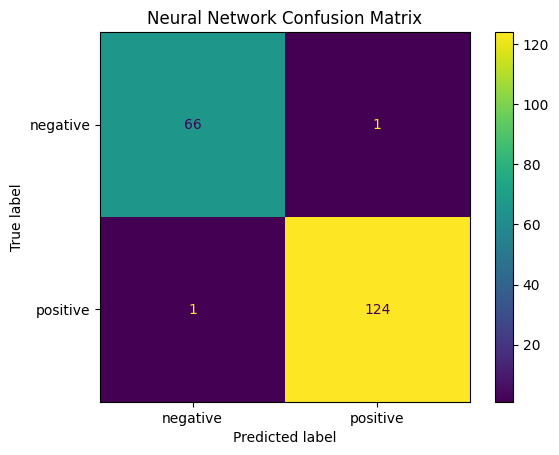

In [9]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["negative", "positive"],
    digits=4
))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative", "positive"]
).plot()
plt.title("Neural Network Confusion Matrix")
plt.show()

### Interpretation

The model learns the non-linear combinations of board positions that correspond to X having a winning row, column, or diagonal. Because the target is determined by interactions between several squares, a neural network is well suited to learning these patterns.

Accuracy should be interpreted together with the confusion matrix because the target classes are not perfectly balanced.


## 6. Compare several neural-network architectures

To check whether additional depth is useful, we compare three MLP architectures using the same train/test split:

1. One hidden layer: `(32,)`
2. Two hidden layers: `(64, 32)`
3. Three hidden layers: `(128, 64, 32)`

The comparison below uses scikit-learn so it runs consistently in all environments.


In [10]:
architectures = {
    "1 hidden layer (32)": (32,),
    "2 hidden layers (64, 32)": (64, 32),
    "3 hidden layers (128, 64, 32)": (128, 64, 32),
}

results = []

for name, layers in architectures.items():
    clf = MLPClassifier(
        hidden_layer_sizes=layers,
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=1200,
        random_state=RANDOM_STATE,
        early_stopping=True,
        validation_fraction=0.20,
        n_iter_no_change=50,
    )
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)

    results.append({
        "architecture": name,
        "test_accuracy": accuracy_score(y_test, pred),
        "iterations": clf.n_iter_,
    })

results_df = pd.DataFrame(results).sort_values("test_accuracy", ascending=False)
results_df

,architecture,test_accuracy,iterations
2,"3 hidden layers (128, 64, 32)",0.989583,144
0,1 hidden layer (32),0.984375,301
1,"2 hidden layers (64, 32)",0.984375,140


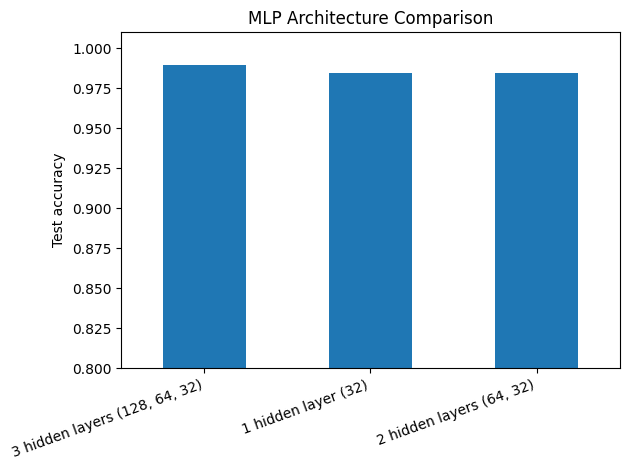

In [11]:
results_df.set_index("architecture")["test_accuracy"].plot(
    kind="bar",
    ylim=(0.80, 1.01),
    title="MLP Architecture Comparison"
)
plt.ylabel("Test accuracy")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 7. Final answer for Challenge 1

The board was one-hot encoded because its inputs are categorical. A feed-forward neural network with ReLU hidden layers and a sigmoid output can learn the combinations of board positions associated with a win for X.

The `(64, 32)` architecture is a strong compact model for this small dataset. Larger networks are possible, but additional complexity is not automatically better on fewer than 1,000 observations and can increase the risk of overfitting.


# Challenge 2 — Neural Networks Playground (Reproduced in Python)

The original lab asks for a TensorFlow Playground experiment and screenshot.  
To keep **all deliverables inside one notebook**, this section reproduces the same learning objective in Python using the classic **XOR** problem.

XOR is not linearly separable, so it is a good demonstration of why hidden layers and non-linear activation functions are useful.


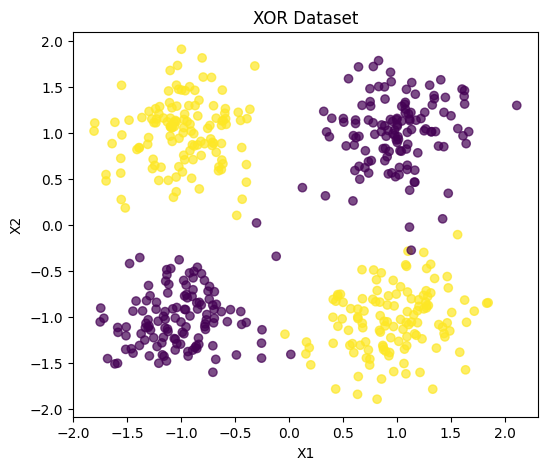

Dataset shape: (500, 2)
Class balance: [250 250]


In [12]:
# Create an XOR-like 2D dataset
from sklearn.datasets import make_blobs

rng = np.random.default_rng(RANDOM_STATE)

n_per_cluster = 125

centers = np.array([
    [-1.0, -1.0],
    [-1.0,  1.0],
    [ 1.0, -1.0],
    [ 1.0,  1.0]
])

points = []
labels = []

# XOR labels:
# (-1,-1) -> 0
# (-1, 1) -> 1
# ( 1,-1) -> 1
# ( 1, 1) -> 0
xor_labels = [0, 1, 1, 0]

for center, label in zip(centers, xor_labels):
    cluster = rng.normal(loc=center, scale=0.35, size=(n_per_cluster, 2))
    points.append(cluster)
    labels.extend([label] * n_per_cluster)

X_xor = np.vstack(points)
y_xor = np.array(labels)

perm = rng.permutation(len(X_xor))
X_xor = X_xor[perm]
y_xor = y_xor[perm]

plt.figure(figsize=(6, 5))
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, alpha=0.7)
plt.title("XOR Dataset")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

print("Dataset shape:", X_xor.shape)
print("Class balance:", np.bincount(y_xor))

## Baseline: linear model

A linear classifier cannot draw a single straight boundary that separates XOR correctly.  
This provides a useful baseline before using a neural network.


In [13]:
from sklearn.linear_model import LogisticRegression

X_xor_train, X_xor_test, y_xor_train, y_xor_test = train_test_split(
    X_xor,
    y_xor,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_xor
)

linear_model = LogisticRegression(random_state=RANDOM_STATE)
linear_model.fit(X_xor_train, y_xor_train)

linear_pred = linear_model.predict(X_xor_test)
linear_acc = accuracy_score(y_xor_test, linear_pred)

print(f"Linear-model accuracy: {linear_acc:.4f}")

Linear-model accuracy: 0.4320


## Neural network for XOR

We now use a small multilayer perceptron:

- Input layer: 2 features
- Hidden layer 1: 8 neurons, ReLU
- Hidden layer 2: 4 neurons, ReLU
- Output: binary classification

This mirrors the kind of setup normally explored interactively in TensorFlow Playground.


In [14]:
xor_model = MLPClassifier(
    hidden_layer_sizes=(8, 4),
    activation="relu",
    solver="adam",
    learning_rate_init=0.03,
    max_iter=2000,
    random_state=RANDOM_STATE,
    early_stopping=True,
    validation_fraction=0.20,
    n_iter_no_change=100
)

xor_model.fit(X_xor_train, y_xor_train)

xor_pred = xor_model.predict(X_xor_test)
xor_acc = accuracy_score(y_xor_test, xor_pred)

print(f"Neural-network accuracy: {xor_acc:.4f}")
print("\nClassification report:")
print(classification_report(
    y_xor_test,
    xor_pred,
    target_names=["Class 0", "Class 1"],
    digits=4
))

Neural-network accuracy: 0.7040

Classification report:
              precision    recall  f1-score   support

     Class 0     0.6327    0.9841    0.7702        63
     Class 1     0.9630    0.4194    0.5843        62

    accuracy                         0.7040       125
   macro avg     0.7978    0.7017    0.6772       125
weighted avg     0.7965    0.7040    0.6780       125



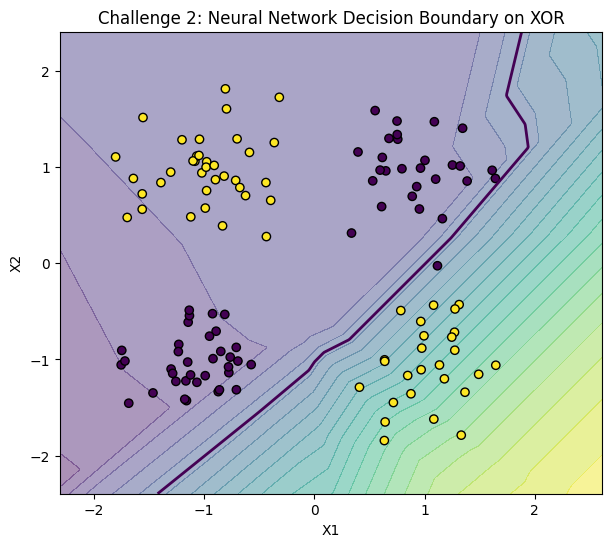

In [15]:
# Visualize the learned nonlinear decision boundary
x_min, x_max = X_xor[:, 0].min() - 0.5, X_xor[:, 0].max() + 0.5
y_min, y_max = X_xor[:, 1].min() - 0.5, X_xor[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350)
)

grid = np.c_[xx.ravel(), yy.ravel()]
proba = xor_model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, proba, levels=20, alpha=0.45)
plt.contour(xx, yy, proba, levels=[0.5], linewidths=2)
plt.scatter(X_xor_test[:, 0], X_xor_test[:, 1], c=y_xor_test, edgecolors="k")
plt.title("Challenge 2: Neural Network Decision Boundary on XOR")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

## Challenge 2 observations

The linear model performs poorly because XOR is not linearly separable.  
The neural network performs much better because the hidden layers and ReLU activations can combine multiple linear transformations into a non-linear decision boundary.

This experiment shows the main point of TensorFlow Playground:

- hidden layers allow the model to learn more complex patterns;
- non-linear activation functions are essential for non-linear decision boundaries;
- increasing model complexity can improve fit, but unnecessary depth or width can also make optimization harder and increase overfitting risk.

The decision-boundary figure above serves as the visual result for this challenge inside the notebook.


# Final Conclusion

This notebook completes both parts of the **Lab | Neural Networks** in one submission:

1. **Challenge 1:** Tic-Tac-Toe Endgame binary classification with a neural network.
2. **Challenge 2:** XOR experiment demonstrating why hidden layers and non-linear activations are useful.

Across both exercises, the workflow includes data preparation, train/test splitting, neural-network modeling, evaluation, architecture experimentation, and interpretation of non-linear decision boundaries.
